# mmb0-1b_smb1-1b_2p Analysis

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 21.02.2025
- Date of Last Modification: 06.04.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries 

In [88]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [89]:
import sys
sys.path.append("../../utils")

In [90]:
import logging
import os
import warnings
import pickle
import random
from datetime import datetime

import anndata as ad
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
import seaborn as sns
import squidpy as sq
from datasets import load_from_disk
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from sklearn.model_selection import train_test_split

from app.infer import infer
from app.train import train
from nichejepa.datasets import prepare_dataset
from nichejepa.utils.config import create_params_from_YAML_wandb_config
from nichejepa.utils.distributed import init_distributed
from nichejepa.utils.evaluation import clustering_metrics, classification_metrics

from analysis_utils import *

## 1.2 Load Config/Params
All setup will be done in the config file. Please edit that file to continue.

In [176]:
# Set params
dataset = 'mmb0-1b_smb1-1b_2p'
tokenizer = 'cell_graph'
# load_timestamp = '29032025_080927_875' # gt_tiny
# load_timestamp = '03042025_224852_256' # gt_small
# load_timestamp = '27032025_163938_061' # gt_base
# load_timestamp = '03042025_224013_784' # gt_large
# load_timestamp = None
load_timestamp = '28052025_090354_995'
model_type = 'test'
read_checkpoint = 'nichejepa-latest.pth.tar' # 'nichejepa-ep1_6.pth.tar'

In [177]:
model_config_folder_path = '/home/aih/sebastian.birk/workspace/projects/nichejepa/configs/model'
artifacts_folder_path = '../../artifacts'
datasets_folder_path = '/home/aih/sebastian.birk/workspace/projects/nichejepa-reproducibility/data/st_data'
token_dict_path = '/home/aih/sebastian.birk/workspace/projects/nichejepa-reproducibility/data/tokenizer_data/token_dictionary_mus_musculus.pkl'

In [178]:
# Set up logger
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

In [179]:
# Load config
if not load_timestamp:
    params = create_params_from_YAML_wandb_config(f'{model_config_folder_path}/{dataset}_{model_type}.yaml',logger)
else:
    params = create_params_from_YAML_wandb_config(f'{artifacts_folder_path}/{dataset}/{load_timestamp}/params.yaml',logger)

if read_checkpoint:
    params['state']['read_checkpoint'] = read_checkpoint
if load_timestamp:
    params['state']['load_checkpoint'] = True

params

INFO:root:Loaded parameters from YAML file.


{'data': {'batch_size': 192,
  'dataset_name': 'mmb0-1b_smb1-1b_2p',
  'n_segments': 7,
  'num_workers': 24,
  'pin_memory': True,
  'precomputed_n_nonzero_tokens': None,
  'precomputed_split': None,
  'random_state': 0,
  'raw_data_folder_path': '/home/aih/sebastian.birk/workspace/projects/nichejepa-reproducibility/data/st_data/silver/mmb0-1b_smb1-1b_2p',
  'sample_subset': False,
  'sampling_strategy': None,
  'seq_len_cell': 256,
  'seq_len_neighborhood': 1536,
  'split': 0.2,
  'stratify': False,
  'test_batch_ids': None,
  'token_dict_folder_path': '/home/aih/sebastian.birk/workspace/projects/nichejepa-reproducibility/data/tokenizer_data/token_dictionary_mus_musculus.pkl',
  'tokenized_data_folder_path': '/home/aih/sebastian.birk/workspace/projects/nichejepa-reproducibility/data/st_data/gold/cell-graph-tokenizer/mmb0-1b_smb1-1b_2p/mmb0-1b_smb1-1b_2p_32_None_None_None_None_None_shifted_log_knn_6_1792.dataset',
  'tokenizer_type': 'cell_graph',
  'val_batch_ids': None},
 'mask': {'b

In [180]:
# Define folder path for saving and loading artifacts
if not load_timestamp:
    current_timestamp = (
        datetime.now().strftime("%d%m%Y_%H%M%S") +
        f"_{datetime.now().microsecond // 1000:03d}")
    folder_path = os.path.join(artifacts_folder_path,
                               params['data']['dataset_name'],
                               current_timestamp)
else:
    folder_path = f'{artifacts_folder_path}/{dataset}/{load_timestamp}'
    
folder_path

'../../artifacts/mmb0-1b_smb1-1b_2p/28052025_090354_995'

## 1.3 Run Notebook Setup

In [181]:
os.makedirs(f'{folder_path}/figures', exist_ok=True)

In [182]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [183]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [184]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [185]:
sc.settings.figdir = f'{folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(6, 4),
    facecolor='white',
    fontsize=10
)

## 1.4 Define Functions

In [186]:
def run_inference(dataset_name,
                  params,
                  read_checkpoint,
                  obs_cols,
                  rerun_inference=False,
                  write_to_disk=True):
    # Load inference results if they exist
    if os.path.exists(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad') and not rerun_inference:
        adata = sc.read_h5ad(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')
    else:
        # Load data
        _, _, test_dataset = prepare_dataset(params)
        test_dataset
        
        # Run model inference
        adata = infer(params,
                      test_dataset,
                      load_folder_path=folder_path,
                      dataset_ids=list(set([batch_id.split('_')[0] for batch_id in params['data']['test_batch_ids']])),
                      obs_cols=obs_cols,
                      agg_type='avg',
                      masked_tokens=None,
                      agg_excluded_tokens=None,
                      cell_gene_ids=[],
                      neighborhood_gene_ids=[])

    # Extract batch from cell ID
    adata.obs["batch"] = [cell_id.split('_')[1].replace('batch', '') for cell_id in adata.obs.index.tolist()]
    
    # Remove missing ground truth
    for obs_col in obs_cols:
        adata = adata[~adata.obs[obs_col].isna()]

    if write_to_disk:
        # Save adata
        adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

    return adata

In [187]:
def compute_embedding_similarity(adata,
                                 emb_keys=['cell', 'neighborhood'],
                                 label='niche_type',
                                 write_to_disk=True):
    for emb_key in emb_keys:
        similarity_stats = compute_similarity_stats(
            adata,
            n_samples=None,
            type_key=label,
            embedding_key=f'{emb_key}_emb_layer_{layer}')

        avg_cos_sim = np.mean(similarity_stats["Mean Similarity"])
    
        cosine_df = pd.DataFrame({
            'metric': [f'avg_{label}_cos_sim'],
            'value': [avg_cos_sim]
        })
        print(f'Average {label} cosine similarity is {avg_cos_sim}.')
        cosine_df.to_csv(f'{folder_path}/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_avg_{label}_cos_sim.csv',
                         index=False)
        
        plot_similarity_heatmaps(
            similarity_stats,
            save_file_path=f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{emb_key}_emb_{label}_cos_sim.svg')

In [188]:
def compute_neighborhood_umap(adata,
                              write_to_disk=True):
    if 'neighborhood_connectivities' not in adata.obsp.keys():
        # Compute UMAP representation for (aggregated) neighborhood gene embeddings
        sc.pp.neighbors(adata,
                        n_neighbors=15,
                        use_rep=f'neighborhood_emb_layer_{layer}',
                        key_added='neighborhood')
    if 'neighborhood_umap' not in adata.obsm.keys():
        sc.tl.umap(adata,
                   neighbors_key='neighborhood',
                   key_added='neighborhood_umap')
    
        if write_to_disk:
            # Save adata
            adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')
    
    if 'cell_connectivities' not in adata.obsp.keys():
        # Compute UMAP representation for (aggregated) cell gene embeddings
        sc.pp.neighbors(adata,
                        n_neighbors=15,
                        use_rep=f'cell_emb_layer_{layer}',
                        key_added='cell')
    if 'cell_umap' not in adata.obsm.keys():
        sc.tl.umap(adata,
                   neighbors_key='cell',
                   key_added='cell_umap')

        if write_to_disk:
            # Save adata
            adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

    return adata

In [189]:
def compute_latent_clusters(adata,
                            emb_keys=['cell', 'neighborhood'],
                            obs_col='niche_type',
                            latent_leiden_resolution_cell=1.0,
                            latent_leiden_resolution_neighborhood=0.4,
                            write_to_disk=True):
    for emb_key in emb_keys:
        latent_leiden_resolutions = []
        if emb_key == 'cell':
            latent_leiden_resolution = latent_leiden_resolution_cell
        elif emb_key == 'neighborhood':
            latent_leiden_resolution = latent_leiden_resolution_neighborhood
        adata.obsm['X_umap'] = adata.obsm[f'{emb_key}_umap']
        # Perform clustering until number of ground truth niches is matched
        i = 0
        n_unique_vals = len(adata.obs[obs_col].value_counts() < 100)
        print(f'Target number of unique values: {n_unique_vals}.')
        n_latent_clusters = 0
        while (n_latent_clusters != n_unique_vals):
            if latent_leiden_resolution in latent_leiden_resolutions:
                latent_leiden_resolution += random.uniform(0.0001, 0.001)
            latent_leiden_resolutions.append(latent_leiden_resolution)
            print(f'Leiden resolution: {latent_leiden_resolution}.')
            latent_cluster_key = f'{emb_key}_emb_leiden_res{str(latent_leiden_resolution).replace(".", "_")}'
            i += 1
            sc.tl.leiden(adata,
                         neighbors_key=emb_key,
                         key_added=latent_cluster_key,
                         resolution=latent_leiden_resolution)
        
            n_latent_clusters = len(adata.obs[latent_cluster_key].value_counts() < 100)
            print(f"Number of latent clusters {n_latent_clusters}.")
            if n_latent_clusters == n_unique_vals:
                break
            elif n_latent_clusters < (n_unique_vals - 8):
                latent_leiden_resolution += 0.1
            elif n_latent_clusters < (n_unique_vals - 5):
                latent_leiden_resolution += 0.05
            elif n_latent_clusters < (n_unique_vals - 3):
                latent_leiden_resolution += 0.02
            elif n_latent_clusters < n_unique_vals:
                latent_leiden_resolution += 0.001
            elif n_latent_clusters > (n_unique_vals + 8):
                latent_leiden_resolution -= 0.1
            elif n_latent_clusters > (n_unique_vals + 5):
                latent_leiden_resolution -= 0.05
            elif n_latent_clusters > (n_unique_vals + 3):
                latent_leiden_resolution -= 0.02
            else:
                latent_leiden_resolution -= 0.001
        
        # Compute metrics and store to disk
        labels = adata.obs[obs_col]
        labels_pred = adata.obs[latent_cluster_key]
        nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
        ari = adjusted_rand_score(labels, labels_pred)
        print(f'NMI is {nmi}. ARI is {ari}.')
        metrics_df = pd.DataFrame({
            'metric': ['NMI', 'ARI'],
            'value': [nmi, ari]
        })
        metrics_df.to_csv(f'{folder_path}/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_metrics.csv',
                          index=False)
        
        # Plot UMAPs
        os.makedirs(f'{folder_path}/figures', exist_ok=True)
        labels = ['batch', obs_col, latent_cluster_key]
        # Plot (aggregated) neighborhood gene embeddings, colored by labels
        for label in labels:
            if len(np.unique(adata.obs[label])) > 1:
                sc.pl.umap(adata,
                           neighbors_key=emb_key,
                           title=(emb_key + "_emb_" + label if emb_key not in label else label),
                           color=label,
                           palette=(custom_palette if label == latent_cluster_key else None),
                           show=False)
                plt.savefig(f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}{"_" + emb_key + "_emb" if emb_key not in label else ""}_{label}_umap.svg',
                            dpi=300,
                            bbox_inches='tight')
        
        # Plot niches in tissue
        batch_ids = adata.obs['batch'].unique().tolist()
        for i, batch_id in enumerate(batch_ids):
            adata_batch = adata[adata.obs['batch'] == batch_id]
            sc.pl.spatial(adata_batch,
                          color=latent_cluster_key,
                          palette=custom_palette,
                          spot_size=spot_sizes[i],
                          save=f'{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg')
            os.rename(f'{folder_path}/figures/show{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg',
                      f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg'.replace("show", ""))
    
        if write_to_disk:
            # Save adata
            adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')
    
    return adata

# 2. Analysis

In [190]:
# Load data
train_dataset, _, test_dataset = prepare_dataset(params)
train_dataset

Dataset({
    features: ['cell_degrees', 'cell_total_counts', 'cell_n_probed_genes', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value_token', 'gene_panel_value_token', 'assay_value_token', 'species_value_token', 'tissue_value_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens', 'cls_tokens'],
    num_rows: 92505
})

In [191]:
train_dataset

Dataset({
    features: ['cell_degrees', 'cell_total_counts', 'cell_n_probed_genes', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value_token', 'gene_panel_value_token', 'assay_value_token', 'species_value_token', 'tissue_value_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens', 'cls_tokens'],
    num_rows: 92505
})

In [192]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=random.randint(40000, 50000))
logger.info(f'Running... (rank: {rank}/{world_size})')

INFO:root:Running... (rank: 0/1)


## 2.1 Run Inference

### 2.1.1 xhs49-1b_1p (Xenium Human Skin Melanoma)

#### 2.1.1.1 Define Config

In [193]:
# Set inference params
layer = params['meta']['enc_depth']
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'
mask_unshared_tokens = False
exclude_unshared_tokens = False
feature_norm = False
params['data']['batch_size'] = 128
params['data']['test_batch_ids'] = [
    '0_batch82',
    '1_batch15']

In [194]:
# Set dataset params
dataset_name = 'mmb0-1b_smb1-1b_2p'
batch_key = 'batch'
emb_key = 'neighborhood'
latent_leiden_resolution = 0.4
spot_sizes = [0.3, 30]

latent_cluster_key = f'{emb_key}_emb_leiden_res{str(latent_leiden_resolution).replace(".", "_")}'

#### 2.1.1.2 Run Model Inference

In [195]:
if mask_unshared_tokens or exclude_unshared_tokens:
    mmb0_adata_raw = sc.read_h5ad('/home/aih/sebastian.birk/workspace/projects/nichejepa-reproducibility/data/st_data/silver/mmb0-1b_smb1-1b_2p/starmap_plus_mouse_cns_batch15.h5ad')
    smb1_adata_raw = sc.read_h5ad('/home/aih/sebastian.birk/workspace/projects/nichejepa-reproducibility/data/st_data/silver/mmb0-1b_smb1-1b_2p/merfish_mouse_brain_batch82.h5ad')
    
    token_dict_path = '/home/aih/sebastian.birk/workspace/projects/nichejepa-reproducibility/data/tokenizer_data/token_dictionary_mus_musculus.pkl'
    
    with open(token_dict_path, 'rb') as f:
        token_dict = pickle.load(f) 
    
    mmb0_gene_tokens = [token_dict[gene] for gene in mmb0_adata_raw.var['ensembl_id'].tolist()]
    smb1_gene_tokens = [token_dict[gene] for gene in smb1_adata_raw.var['ensembl_id'].tolist()]
    
    overlapping_gene_tokens = set(mmb0_gene_tokens) & set(smb1_gene_tokens)
    non_overlapping_gene_tokens = (set(mmb0_gene_tokens) | set(smb1_gene_tokens)) - overlapping_gene_tokens
    overlapping_gene_tokens = list(overlapping_gene_tokens)
    non_overlapping_gene_tokens = list(non_overlapping_gene_tokens)
else:
    overlapping_gene_tokens = None
    non_overlapping_gene_tokens = None

In [196]:
# Run model inference
adata = infer(params,
              train_dataset,
              load_folder_path=folder_path,
              agg_type=agg_type,
              masked_tokens=non_overlapping_gene_tokens if mask_unshared_tokens else None,
              agg_excluded_tokens=non_overlapping_gene_tokens if exclude_unshared_tokens else None,
              feature_norm=feature_norm,
              #cell_gene_ids=[1031],
              #neighborhood_gene_ids=[1031]
             )

# Save adata
adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}{"_mask_unshared_tokens" if mask_unshared_tokens else ""}{"_exclude_unshared_tokens" if exclude_unshared_tokens else ""}{"_feature_norm" if feature_norm else ""}.h5ad')

INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCountEncoder(
    (token_embed): Embedding(2785, 768, padding_idx=0)
    (seg_embed): Embedding(8, 768, padding_idx=0)
    (blocks): ModuleList(
      (0-2): 3 x Block(
        (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=768, out_features=2304, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=768, out_features=768, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=3072, out_features=768, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/ictstr01/home/aih/sebastian.birk/workspace/projects/nichejepa/src/app/infer.py:351: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,
/home/aih/sebastian.birk/miniconda3/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
723it [07:54,  1.52it/s]
/home/aih/sebastian.birk/miniconda3/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Loading metadata AnnDatas...
Loading AnnData objects from /home/aih/sebastian.birk/workspace/projects/nichejepa-reproducibility/data/st_data/silver/mmb0-1b_smb1-1b_2p.
Loading AnnData objects from /home/aih/sebastian.birk/workspace/projects/nichejepa-reproducibility/data/st_data/silver/mmb0-1b_smb1-1b_2p/.ipynb_checkpoints.


/home/aih/sebastian.birk/miniconda3/lib/python3.10/site-packages/anndata/_core/merge.py:1434: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


In [197]:
# Extract batch from cell ID
adata.obs["batch"] = [cell_id.split('_')[1].replace('batch', '') for cell_id in adata.obs.index.tolist()]

In [198]:
# Compute UMAP representation for (aggregated) gene embeddings
if F'{emb_key}_connectivities' not in adata.obsp.keys():
    print("Computing sc.pp.neighbors...")
    sc.pp.neighbors(adata,
                    n_neighbors=15,
                    use_rep=f'{emb_key}_emb_layer_{layer}',
                    key_added=emb_key)
if f'{emb_key}_umap' not in adata.obsm.keys():
    print("Computing sc.tl.umap...")
    sc.tl.umap(adata,
               neighbors_key=emb_key,
               key_added=f'{emb_key}_umap')

Computing sc.pp.neighbors...
Computing sc.tl.umap...


In [199]:
sc.tl.leiden(adata,
             neighbors_key=emb_key,
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

... storing 'batch' as categorical


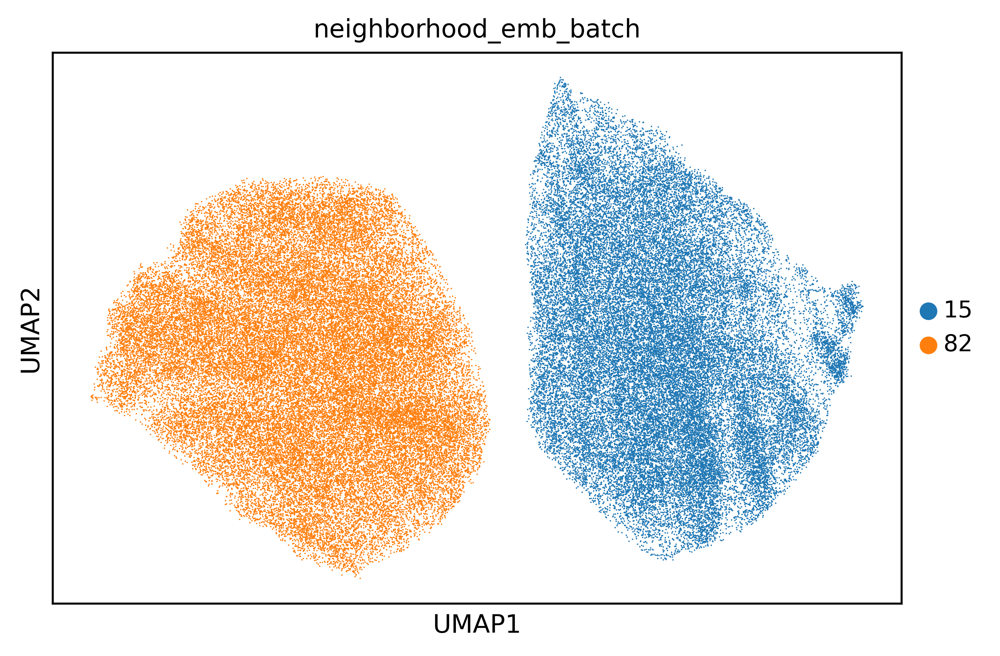

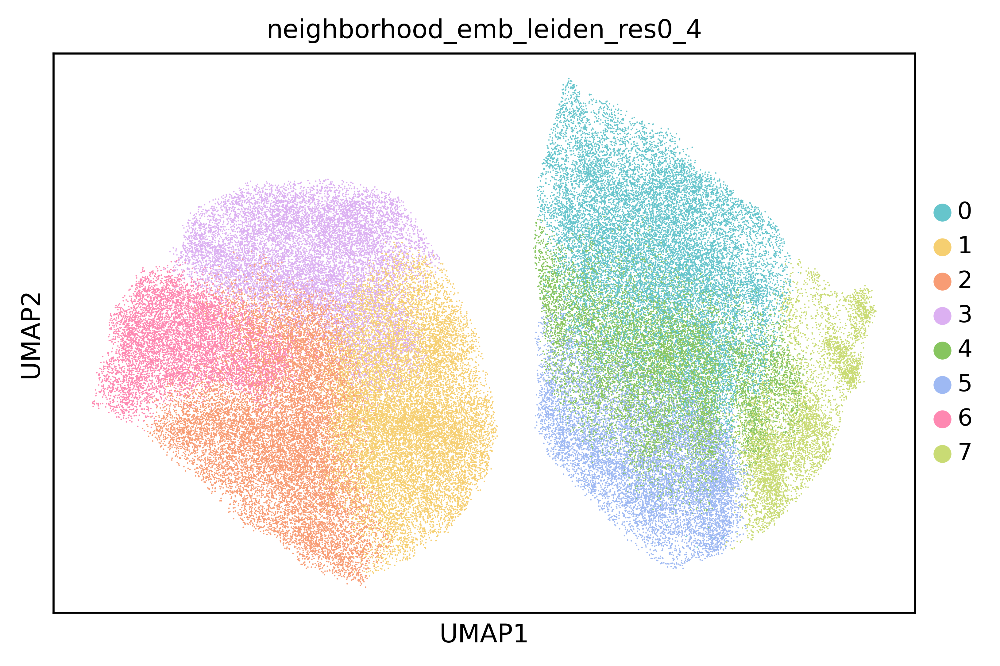

In [200]:
adata.obsm['X_umap'] = adata.obsm[f'{emb_key}_umap']

label = 'batch'
sc.pl.umap(adata,
           neighbors_key=emb_key,
           title=(emb_key + "_emb_" + label if emb_key not in label else label),
           color=label,
           palette=(custom_palette if label == latent_cluster_key else None),
           show=False)
plt.savefig(f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}{"_mask_unshared_tokens" if mask_unshared_tokens else ""}{"_exclude_unshared_tokens" if exclude_unshared_tokens else ""}{"_feature_norm" if feature_norm else ""}{"_" + emb_key + "_emb" if emb_key not in label else ""}_{label}_umap.svg',
            dpi=300,
            bbox_inches='tight')

label = latent_cluster_key
sc.pl.umap(adata,
           neighbors_key=emb_key,
           title=(emb_key + "_emb_" + label if emb_key not in label else label),
           color=label,
           palette=(custom_palette if label == latent_cluster_key else None),
           show=False)
plt.savefig(f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}{"_mask_unshared_tokens" if mask_unshared_tokens else ""}{"_exclude_unshared_tokens" if exclude_unshared_tokens else ""}{"_feature_norm" if feature_norm else ""}{"_" + emb_key + "_emb" if emb_key not in label else ""}_{label}_umap.svg',
            dpi=300,
            bbox_inches='tight')

/tmp/ipykernel_2415083/393402510.py:5: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


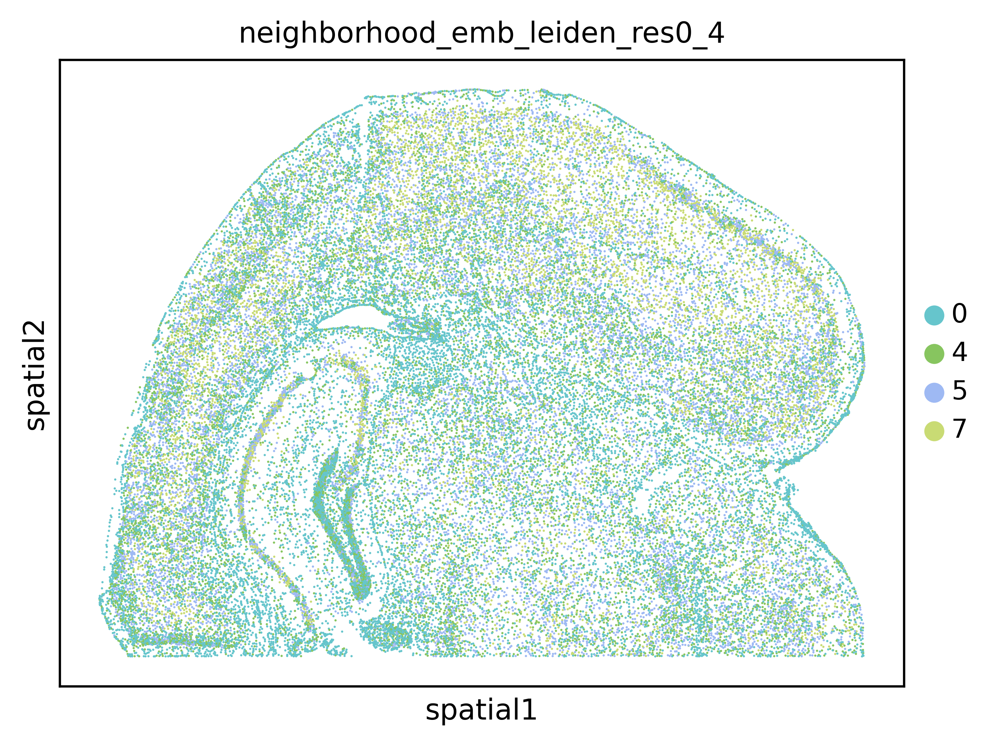

/tmp/ipykernel_2415083/393402510.py:14: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


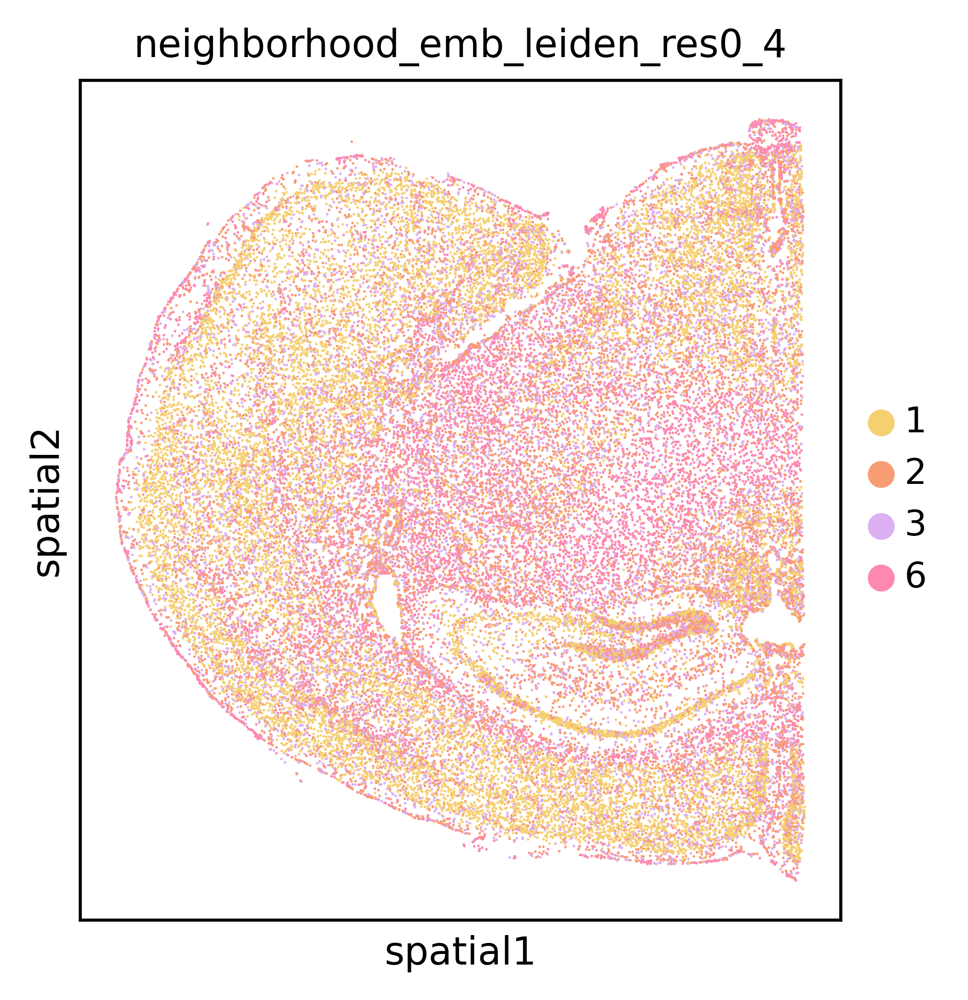

In [201]:
# Plot tissue sections colored by latent clusters
mmb0_adata = adata[adata.obs['batch'] == '82']
smb1_adata = adata[adata.obs['batch'] == '15']

sc.pl.spatial(
    smb1_adata,
    color=latent_cluster_key,
    spot_size=0.1,
    save=f'{read_checkpoint.split("-")[1].split(".")[0]}_smb1-1b{"_mask_unshared_tokens" if mask_unshared_tokens else ""}{"_exclude_unshared_tokens" if exclude_unshared_tokens else ""}{"_feature_norm" if feature_norm else ""}_{latent_cluster_key}.svg')

os.rename(f'{folder_path}/figures/show{read_checkpoint.split("-")[1].split(".")[0]}_smb1-1b{"_mask_unshared_tokens" if mask_unshared_tokens else ""}{"_exclude_unshared_tokens" if exclude_unshared_tokens else ""}{"_feature_norm" if feature_norm else ""}_{latent_cluster_key}.svg',
          f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_smb1-1b{"_mask_unshared_tokens" if mask_unshared_tokens else ""}{"_exclude_unshared_tokens" if exclude_unshared_tokens else ""}{"_feature_norm" if feature_norm else ""}_{latent_cluster_key}.svg'.replace("show", ""))

sc.pl.spatial(
    mmb0_adata,
    color=latent_cluster_key,
    spot_size=20,
    save=f'{read_checkpoint.split("-")[1].split(".")[0]}_mmb0-1b{"_mask_unshared_tokens" if mask_unshared_tokens else ""}{"_exclude_unshared_tokens" if exclude_unshared_tokens else ""}{"_feature_norm" if feature_norm else ""}_{latent_cluster_key}.svg')

os.rename(f'{folder_path}/figures/show{read_checkpoint.split("-")[1].split(".")[0]}_mmb0-1b{"_mask_unshared_tokens" if mask_unshared_tokens else ""}{"_exclude_unshared_tokens" if exclude_unshared_tokens else ""}{"_feature_norm" if feature_norm else ""}_{latent_cluster_key}.svg',
          f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_mmb0-1b{"_mask_unshared_tokens" if mask_unshared_tokens else ""}{"_exclude_unshared_tokens" if exclude_unshared_tokens else ""}{"_feature_norm" if feature_norm else ""}_{latent_cluster_key}.svg'.replace("show", ""))

  Class 1 Class 2  Mean Similarity  Variance Similarity
0      15      15         0.542806             0.014662
1      15      82         0.416657             0.003177
2      82      15         0.416663             0.003177
3      82      82         0.480908             0.013666
Average batch cosine similarity is 0.46425861120224.





In [202]:
compute_embedding_similarity(adata,
                             emb_keys=[emb_key],
                             label=batch_key,
                             write_to_disk=False)